C:\Users\key\AppData\Local\Temp\ipykernel_12400\4050189639.py:10: DtypeWarning: Columns (1,2,3,11,12) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


Columns: ['domain', 'ranking', 'mld_res', 'mld.ps_res', 'card_rem', 'ratio_Rrem', 'ratio_Arem', 'jaccard_RR', 'jaccard_RA', 'jaccard_AR', 'jaccard_AA', 'jaccard_ARrd', 'jaccard_ARrem', 'label']
Dataset size: (96005, 14)

LOGISTIC REGRESSION - URL CLASSIFICATION

Accuracy: 95.62 %

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.94      0.97      0.96      2001
   Malicious       0.97      0.94      0.96      1999

    accuracy                           0.96      4000
   macro avg       0.96      0.96      0.96      4000
weighted avg       0.96      0.96      0.96      4000



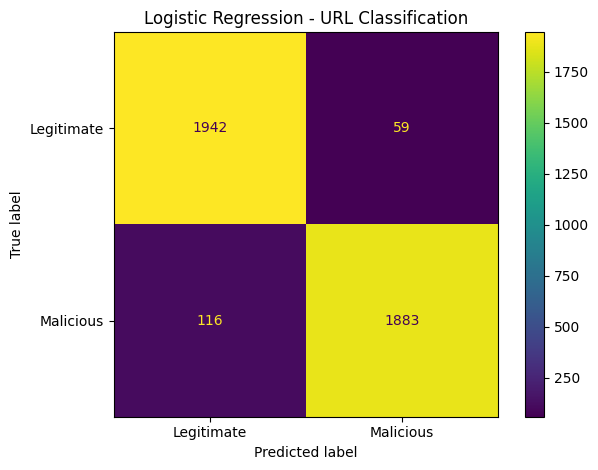

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# Load dataset
df = pd.read_csv(
    "urlset.csv",
    encoding="latin1",
    on_bad_lines="skip",
    low_memory=False
)

print("Columns:", df.columns.tolist())
print("Dataset size:", df.shape)

# Select URL and label
X = df["domain"].astype(str)
y = pd.to_numeric(df["label"], errors="coerce")

# Remove invalid labels
valid = y.notna()
X = X[valid]
y = y[valid].astype(int)

# Use 20,000 samples for faster execution
n = min(20000, len(X))

sample = pd.DataFrame({
    "domain": X,
    "label": y
}).sample(n=n, random_state=42)

X = sample["domain"]
y = sample["label"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert URLs to numerical features
vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    max_features=10000
)

X_train = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)

# Logistic Regression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Results
print("\n" + "=" * 50)
print("LOGISTIC REGRESSION - URL CLASSIFICATION")
print("=" * 50)

print("\nAccuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Malicious"]
))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Legitimate", "Malicious"]
)

plt.title("Logistic Regression - URL Classification")
plt.tight_layout()
plt.show()